# TS07 - Filtrado digital lineal de ECG
**Informe de análisis teórico y numérico**  
**Integrantes:** Daniela Rolando Cabañas y Claudia López De Santa Cirila

## 1. Introducción
En este trabajo se diseña y analiza el comportamiento de filtros digitales (FIR e IIR) aplicados a una señal de ECG muestreada a 1000 Hz. El objetivo es aplicar los cambios necesarios para que se asemeje a los latidos promedio.

In [52]:
import numpy as np
import scipy.io as sio
import scipy.signal as sig
import matplotlib.pyplot as plt

## 2. Carga de Datos

In [53]:
mat_struct = sio.loadmat('./ecg.mat') 
ecg_one_lead = mat_struct['ecg_lead'].flatten()
hb_1 = mat_struct['heartbeat_pattern1'].flatten()
hb_2 = mat_struct['heartbeat_pattern2'].flatten()
qrs_detections = mat_struct['qrs_detections'].flatten()

## 3. Desarrollo y resultados

### a) Diseño para los filtros digitales para la señal de ECG.

In [ ]:
fs = 1000 # Hz
nyq_frec = fs / 2
ripple = 1 # dB
atenuacion = 40 # dB

ws1 = 1  # Hz
wp1 = 3  # Hz
wp2 = 25 # Hz
ws2 = 35 # Hz

# plantilla normalizada a Nyquist en dB
frecs = np.array([0.0,         ws1,         wp1,     wp2,     ws2,         nyq_frec   ]) / nyq_frec
gains = np.array([-atenuacion, -atenuacion, -ripple, -ripple, -atenuacion, -atenuacion])

Se define una plantilla pasabanda con banda de paso entre $3\text{ Hz}$ y $25\text{ Hz}$ con un ripple máximo de $1\text{ dB}$, y bandas de rechazo por debajo de $1\text{ Hz}$ y por encima de $35\text{ Hz}$ con una atenuación mínima de $40\text{ dB}$.

### b) Procedimiento para establecer los valores.
Se establecieron los siguientes parámetros en la platilla: <br>
1. Banda de rechazo inferior (ws1) a 1 Hz, ya que al observar la señal se ve que las variaciones son muy lentas indicando que su energía está por debajo de 1 Hz. <br> Banda de rechazo superior (ws2) a 35 Hz, ya que por encima de ese valor aparece ruido.
2. Banda de paso (wp1 - wp2) a un rango 3-25 Hz, ya que al analizar el espectro de frecuencia de un latido normal se observa que la mayor parte d ela información está en dicho rango.
3. Atenuaciones (ripple y atenuacion) a 1db y 40 db respectivamente, para que la amplitud de los latidos no cambie y para que el ruido quede eliminado.


### c) Diseño de dos filtros FIR y dos filtros IIR.
#### 1. Filtros FIR.

In [55]:
numtaps_win = 2501
fir_win = sig.firwin2(numtaps_win, frecs, [0, 0, 1, 1, 0, 0], window=('kaiser', 5.0))

fir_ls_hp = sig.firls(1501, [0, ws1, wp1, nyq_frec], [0, 0, 1, 1], fs=fs)
fir_ls_lp = sig.firls(1001, [0, wp2, ws2, nyq_frec], [1, 1, 0, 0], fs=fs)
fir_ls = np.convolve(fir_ls_hp, fir_ls_lp)
numtaps_ls = len(fir_ls)

fir_remez_hp = sig.remez(1501, [0, ws1, wp1, nyq_frec], [0, 1], weight=[10, 1], fs=fs)
fir_remez_lp = sig.remez(1001, [0, wp2, ws2, nyq_frec], [1, 0], weight=[1, 10], fs=fs)
fir_remez = np.convolve(fir_remez_hp, fir_remez_lp)
numtaps_remez = len(fir_remez)

#### 2. Filtros IIR.

In [56]:
wp = [wp1, wp2]
ws = [ws1, ws2]

sos_butter = sig.iirdesign(wp=wp, ws=ws, gpass=ripple, gstop=atenuacion, ftype='butter', output='sos', fs=fs)
sos_cheby1 = sig.iirdesign(wp=wp, ws=ws, gpass=ripple, gstop=atenuacion, ftype='cheby1', output='sos', fs=fs)
sos_ellip  = sig.iirdesign(wp=wp, ws=ws, gpass=ripple, gstop=atenuacion, ftype='ellip',  output='sos', fs=fs)


#### 3. Comparación.

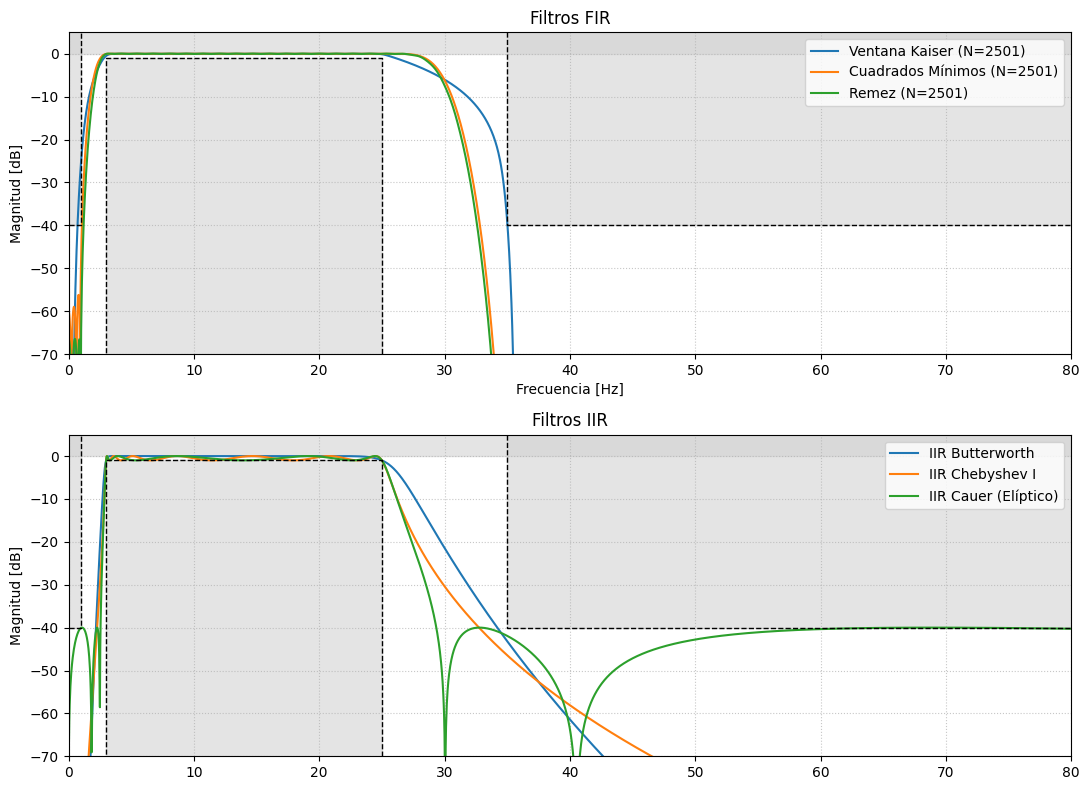

In [ ]:
w_iir, h_butter = sig.sosfreqz(sos_butter, worN=16384, fs=fs)
_,     h_cheby1 = sig.sosfreqz(sos_cheby1, worN=16384, fs=fs)
_,     h_ellip  = sig.sosfreqz(sos_ellip,  worN=16384, fs=fs)

w_fir, h_win    = sig.freqz(fir_win,   worN=16384, fs=fs)
_,     h_ls     = sig.freqz(fir_ls,    worN=16384, fs=fs)
_,     h_remez  = sig.freqz(fir_remez, worN=16384, fs=fs)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8))


def plot_plantilla(ax, xlim):
    # zonas prohibidas (marcadas)
    ax.fill([0, ws1, ws1, 0], [-atenuacion, -atenuacion, 5, 5], color='lightgray', alpha=0.6)
    ax.fill([ws2, nyq_frec, nyq_frec, ws2], [-atenuacion, -atenuacion, 5, 5], color='lightgray', alpha=0.6)
    ax.fill([wp1, wp2, wp2, wp1], [-80, -80, -ripple, -ripple], color='lightgray', alpha=0.6)
    ax.fill([0, nyq_frec, nyq_frec, 0], [0, 0, 5, 5], color='lightgray', alpha=0.6)
    
    ax.plot([0, ws1, ws1], [-atenuacion, -atenuacion, 5], 'k--', lw=1)
    ax.plot([wp1, wp1, wp2, wp2], [-80, -ripple, -ripple, -80], 'k--', lw=1)
    ax.plot([ws2, ws2, nyq_frec], [5, -atenuacion, -atenuacion], 'k--', lw=1)
    ax.set_xlim(xlim)
    ax.set_ylim([-70, 5])
    ax.grid(True, which='both', linestyle=':', alpha=0.7)
    ax.set_ylabel('Magnitud [dB]')

# Gráfico FIR
ax1.plot(w_fir, 20*np.log10(np.maximum(np.abs(h_win),   1e-10)), label=f'Ventana Kaiser (N={numtaps_win})')
ax1.plot(w_fir, 20*np.log10(np.maximum(np.abs(h_ls),    1e-10)), label=f'Cuadrados Mínimos (N={numtaps_ls})')
ax1.plot(w_fir, 20*np.log10(np.maximum(np.abs(h_remez), 1e-10)), label=f'Remez (N={numtaps_remez})')
plot_plantilla(ax1, [0, 80])
ax1.set_title('Filtros FIR')
ax1.set_xlabel('Frecuencia [Hz]')
ax1.legend(loc='upper right')

# Gráfico IIR
ax2.plot(w_iir, 20*np.log10(np.maximum(np.abs(h_butter), 1e-10)), label='IIR Butterworth')
ax2.plot(w_iir, 20*np.log10(np.maximum(np.abs(h_cheby1), 1e-10)), label='IIR Chebyshev I')
ax2.plot(w_iir, 20*np.log10(np.maximum(np.abs(h_ellip),  1e-10)), label='IIR Cauer (Elíptico)')
plot_plantilla(ax2, [0, 80])
ax2.set_title('Filtros IIR')
ax2.legend(loc='upper right')


plt.tight_layout()
plt.show()

Se puede observar que las curvas están dentro de los márgenes definidios sin evadir las zonas prohibidas en ambos casos, cumpliendose además: <br>
1. Banda de paso: en ambas gráficas se observa que se mantiene plana cerca de 0 dB entiendo que se cumple el margen permitido de 1 dB de ripple.
2. Bandas de rechazo: entre 1-35 Hz las curvas de respuesta caen por debajo de - 40 dB que es la atenuación mínima indicada para asegurar eliminar el ruido. <br>

Se puede ver que en el caso de los filtros FIR puede haber más problemas en el rango [1, 3] Hz para lograr una pendiente que no se salga de los márgenes.

### d) Evaluar rendimiento

In [58]:
# se elige un filtro de cada tipo para comparar

ECG_f_remez = sig.lfilter(fir_remez, 1.0, ecg_one_lead)
ECG_f_butter = sig.sosfiltfilt(sos_butter, ecg_one_lead)

demora = (len(fir_remez) - 1) // 2 
cant_muestras = len(ecg_one_lead)

#### 1. Verificar que filtra las señales interferentes
Para ello, se grafica la señal originial, ek filtro FIR Remez y el filtro IIR Butterworth. Se grafica en un tramo corto para observar la modificación donde la señal tiene interferencias.

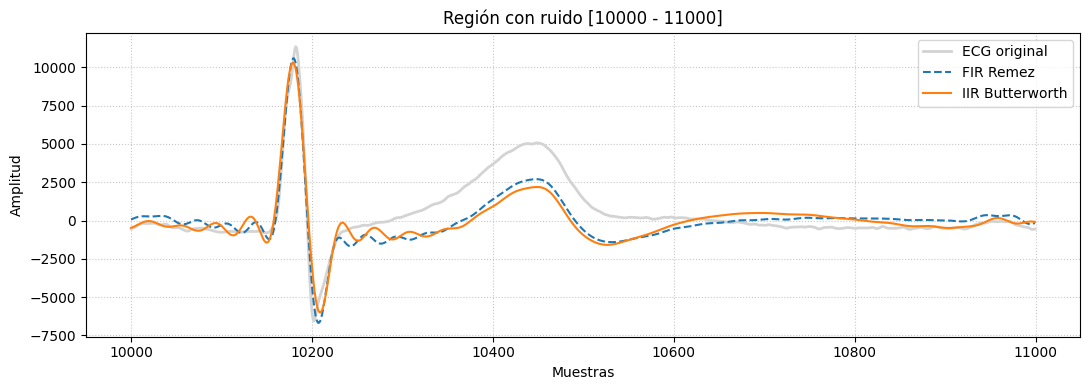

In [66]:
zoom_ruido = np.arange(10000, min(cant_muestras, 11000), dtype='uint')
    
plt.figure(figsize=(11, 4))
plt.plot(zoom_ruido, ecg_one_lead[zoom_ruido], label='ECG original', color='lightgray', linewidth=2)
plt.plot(zoom_ruido, ECG_f_remez[zoom_ruido + demora], label='FIR Remez', linestyle='--', linewidth=1.5)
plt.plot(zoom_ruido, ECG_f_butter[zoom_ruido], label='IIR Butterworth', linewidth=1.5)
    
plt.title(f'Región con ruido [{10000} - {11000}]')
plt.ylabel('Amplitud')
plt.xlabel('Muestras')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Se observa que los filtros "limpian" la señal en estas zonas donde hay ruido. En la gráfica que se centra la señal alrededor del 0, manteniendo la forma pero eliminando la oscilación.

#### 2. Verificar que es inocuo en las zonas donde no hay interferentes.
Para ello, se generan gráficas con tramos más largos en zonas más adelante, donde la ECG original ya es limpia; así se puede comprobar que los filtros no deforman la señal cuando no hay ruido.

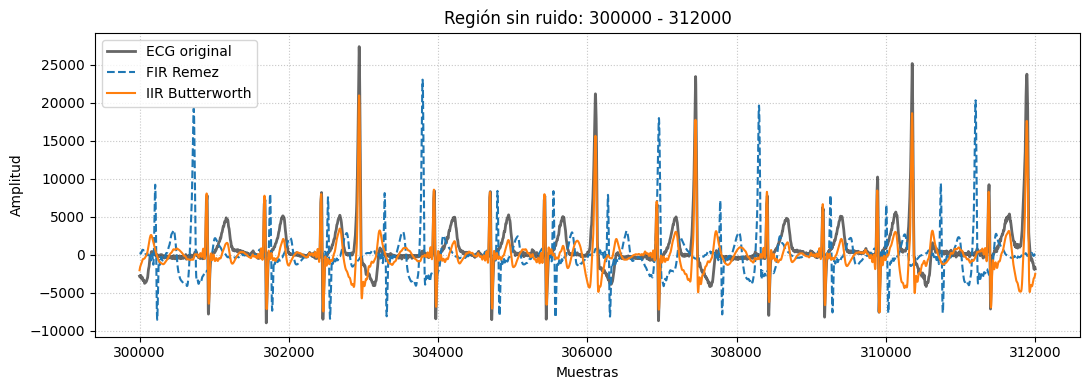

In [74]:
inicio = int(5 * 60 * fs)
fin = int(5.2 * 60 * fs)
zoom = np.arange(max(0, inicio), min(cant_muestras, fin), dtype='uint')
    
plt.figure(figsize=(11, 4))
plt.plot(zoom, ecg_one_lead[zoom], label='ECG original', color='black', linewidth=2, alpha=0.6)
plt.plot(zoom, ECG_f_remez[zoom + demora], label='FIR Remez', linestyle='--', linewidth=1.5)
plt.plot(zoom, ECG_f_butter[zoom], label='IIR Butterworth', linewidth=1.5)
    
plt.title(f'Región sin ruido: {inicio} - {fin}')
plt.ylabel('Amplitud')
plt.xlabel('Muestras')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Podemos decir que es inocuo, ya que se observa que en zonas sin ruido la señal original no se ve considerablemnete modificada. Se puede ver una leve disminución en los picos con mayor amplitud, peor mantiene su forma.

## 4. Bonus: Proponer otra señal.

## 1. Carga de datos

In [69]:
ppg = np.load('ppg_sin_ruido.npy')
# plt.figure()
# plt.plot(ppg)


## 2. Origen y digitalización
Esta señala de PPG se obtuvo de la TS5, se elige ya que, al igual que la vista en esta práctica, refleja actividad cardíaca con ruido. <br>

Esta señal eléctrica, que proviene de un sensor óptico que capta las variaciones, se digitaliza mediante una amplificación, y un paso por un filtro pasa-bajos y un conversor ADC que la muestrea. Se obtiene la secuencia numérica discreta almacenada en el archivo _PPG.csv_.

## 3. Desarrollo y resultados.

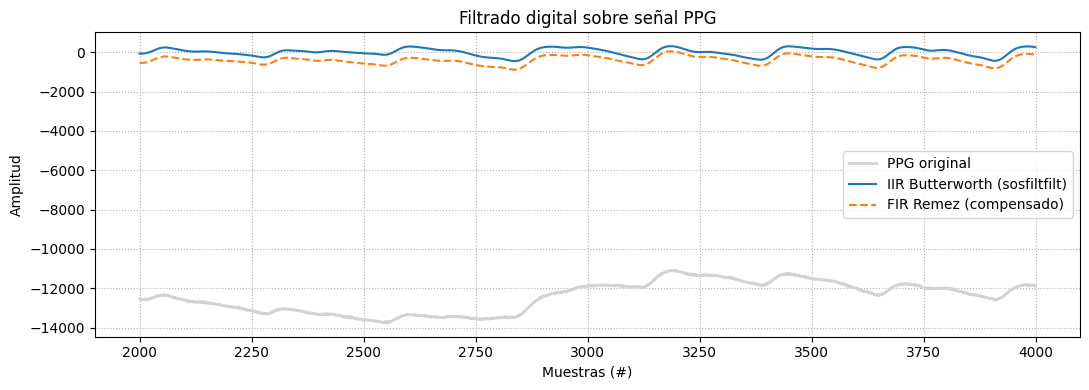

In [ ]:
ppg = np.loadtxt('./PPG.csv')
fs_ppg = 400

wp, ws = [0.7, 8.0], [0.2, 15.0]
fir_ppg = sig.firwin(numtaps=801, cutoff=[0.7, 8.0], pass_zero=False, fs=fs_ppg)
sos_ppg = sig.iirdesign(wp=wp, ws=ws, gpass=1, gstop=40, ftype='butter', output='sos', fs=fs_ppg)

ppg_f_fir = sig.lfilter(fir_ppg, 1.0, ppg)
demora = (len(fir_ppg) - 1) // 2
ppg_f_iir = sig.sosfiltfilt(sos_ppg, ppg)

zoom = np.arange(2000, 4000)
plt.figure(figsize=(11, 4))
plt.plot(zoom, ppg[zoom], label='PPG original', color='lightgray', linewidth=2)
plt.plot(zoom, ppg_f_iir[zoom], label='IIR Butterworth')
plt.plot(zoom, ppg_f_fir[zoom + demora], label='FIR Remez', linestyle='--')
plt.title('Filtrado digital sobre señal PPG')
plt.xlabel('Muestras (#)')
plt.ylabel('Amplitud')
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

En este caso al aplicar los filtros FIR e IIR a la señal PPG original, ambos eliminan el desplazamiento centralizando la señal en 0. Además suavizan el ruido manteniendo la forma limpia y sin modificar su morfología.